# Classification Track (Part A) — Verdict Outcome Tendency Prediction
Loads preprocessed data from `preprocessing.ipynb` and runs the 5 Part-A classification algorithms and their evaluation.

**Requires `preprocessing.ipynb` to have been run first** (produces `data/processed/model_ready_data.pkl`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                              classification_report)
import time

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="colorblind")
RANDOM_STATE = 42

### Load preprocessed train/test data

In [2]:
import joblib

artifacts = joblib.load("../data/processed/model_ready_data.pkl")
X_train_final = artifacts["X_train_final"]
X_test_final = artifacts["X_test_final"]
y_clf_train = artifacts["y_clf_train"]
y_clf_test = artifacts["y_clf_test"]
RANDOM_STATE = artifacts["RANDOM_STATE"]

print("Loaded preprocessed data. X_train_final shape:", X_train_final.shape)

Loaded preprocessed data. X_train_final shape: (194879, 37)


---
### Classification modelling (Part A)

In [3]:
# Class order used consistently everywhere below (confusion matrices, ROC-AUC column order, plots).
CLASS_LABELS = sorted(y_clf_train.unique().tolist())
print("Class order:", CLASS_LABELS)

results_clf = []          # list of dicts -> feeds the D2 comparison table
fitted_models_clf = {}    # name -> fitted estimator
test_preds_clf = {}       # name -> predicted labels on X_test_final
test_probas_clf = {}      # name -> predicted probabilities on X_test_final (n_samples, n_classes)

def evaluate_classifier(name, y_true, y_pred, y_proba, fit_seconds, classes):
    """Compute Accuracy / weighted Precision / Recall / F1 / weighted OvR ROC-AUC, print a full
    classification report, plot the confusion matrix, and log a summary row into `results_clf`.
    `classes` MUST be the estimator's own `.classes_` order (also the column order of y_proba)."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    # Multi-class -> One-vs-Rest ROC-AUC, per rubric.
    roc_auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted", labels=classes)

    print(f"\n===== {name} =====")
    print(f"Accuracy={acc:.4f}  Precision(weighted)={prec:.4f}  Recall(weighted)={rec:.4f}  "
          f"F1(weighted)={f1:.4f}  ROC-AUC(OvR, weighted)={roc_auc:.4f}  (fit time {fit_seconds:.1f}s)")
    print(classification_report(y_true, y_pred, labels=classes, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

    results_clf.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec,
                         "F1": f1, "ROC_AUC_OvR": roc_auc, "Fit_Seconds": fit_seconds})
    return acc, prec, rec, f1, roc_auc

Class order: ['Dismissed', 'Judgment', 'Settled', 'Statistical', 'Transferred']



===== Logistic Regression =====
Accuracy=0.4425  Precision(weighted)=0.5654  Recall(weighted)=0.4425  F1(weighted)=0.4637  ROC-AUC(OvR, weighted)=0.7576  (fit time 3.3s)
              precision    recall  f1-score   support

   Dismissed       0.75      0.36      0.49     22863
    Judgment       0.42      0.41      0.41      9620
     Settled       0.47      0.63      0.54     10772
 Statistical       0.10      0.47      0.16      1485
 Transferred       0.28      0.46      0.34      3980

    accuracy                           0.44     48720
   macro avg       0.40      0.47      0.39     48720
weighted avg       0.57      0.44      0.46     48720



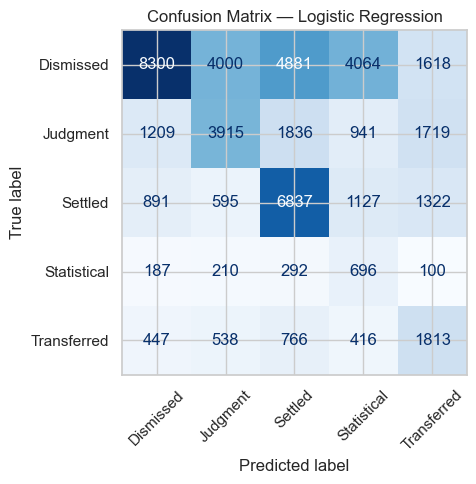

(0.4425492610837438,
 0.5654141831270527,
 0.4425492610837438,
 0.4637459505516463,
 0.7575999172040594)

In [4]:
t0 = time.time()
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
log_reg.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_log = log_reg.predict(X_test_final)
proba_log = log_reg.predict_proba(X_test_final)  # columns ordered per log_reg.classes_

fitted_models_clf["Logistic Regression"] = log_reg
test_preds_clf["Logistic Regression"] = pred_log
test_probas_clf["Logistic Regression"] = proba_log

evaluate_classifier("Logistic Regression", y_clf_test, pred_log, proba_log, fit_seconds,
                     classes=log_reg.classes_.tolist())

In [5]:
# Coefficient / odds interpretation -- one row of coefficients per class (One-vs-Rest style internally,
# since LogisticRegression with >2 classes fits one coefficient vector per class).
coef_df = pd.DataFrame(log_reg.coef_, index=log_reg.classes_, columns=X_train_final.columns)
odds_ratios = np.exp(coef_df)  # exponentiate the log-odds coefficients -> odds ratios

print("Top 5 features (by |coefficient|) driving each class, with their odds ratio:")
for cls in log_reg.classes_:
    top_feats = coef_df.loc[cls].sort_values(key=abs, ascending=False).head(5)
    print(f"\n{cls}:")
    for feat, coef_val in top_feats.items():
        print(f"    {feat:30s}  coef={coef_val:+.3f}   odds_ratio={odds_ratios.loc[cls, feat]:.3f}")

Top 5 features (by |coefficient|) driving each class, with their odds ratio:

Dismissed:
    PC30                            coef=+1.100   odds_ratio=3.003
    PC34                            coef=-0.907   odds_ratio=0.404
    PC33                            coef=-0.840   odds_ratio=0.432
    PC35                            coef=-0.776   odds_ratio=0.460
    PC29                            coef=-0.659   odds_ratio=0.518

Judgment:
    PC36                            coef=+1.149   odds_ratio=3.154
    PC30                            coef=-0.908   odds_ratio=0.403
    PC27                            coef=-0.807   odds_ratio=0.446
    PC37                            coef=+0.797   odds_ratio=2.219
    PC33                            coef=-0.747   odds_ratio=0.474

Settled:
    PC28                            coef=+0.952   odds_ratio=2.592
    PC11                            coef=-0.687   odds_ratio=0.503
    PC8                             coef=-0.674   odds_ratio=0.509
    PC4            

Stratified subsample class balance (should match the full training set's class split):
CASE_OUTCOME
Dismissed      0.469
Settled        0.221
Judgment       0.197
Transferred    0.082
Statistical    0.030
Name: proportion, dtype: float64

===== KNN Classifier =====
Accuracy=0.5709  Precision(weighted)=0.5597  Recall(weighted)=0.5709  F1(weighted)=0.5578  ROC-AUC(OvR, weighted)=0.7631  (fit time 0.0s)
              precision    recall  f1-score   support

   Dismissed       0.63      0.73      0.68     22863
    Judgment       0.52      0.41      0.46      9620
     Settled       0.50      0.55      0.53     10772
 Statistical       0.50      0.18      0.27      1485
 Transferred       0.43      0.24      0.31      3980

    accuracy                           0.57     48720
   macro avg       0.52      0.42      0.45     48720
weighted avg       0.56      0.57      0.56     48720



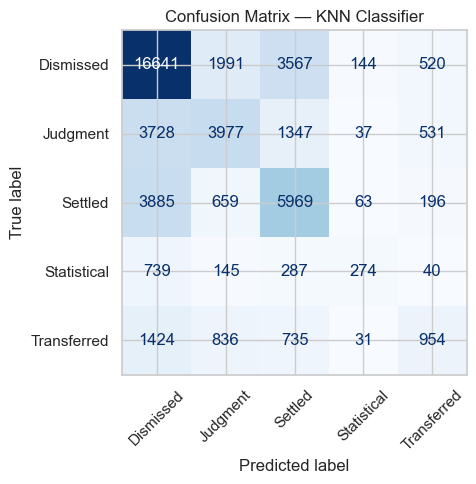

(0.5709154351395731,
 0.5596743799606415,
 0.5709154351395731,
 0.5577560945265388,
 0.763065442613126)

In [6]:
KNN_SVC_SAMPLE_SIZE = 15000
X_train_small, _, y_clf_train_small, _ = train_test_split(
    X_train_final, y_clf_train,
    train_size=KNN_SVC_SAMPLE_SIZE, stratify=y_clf_train, random_state=RANDOM_STATE
)
print("Stratified subsample class balance (should match the full training set's class split):")
print(y_clf_train_small.value_counts(normalize=True).round(3))

t0 = time.time()
knn_clf = KNeighborsClassifier(n_neighbors=10, weights="distance", n_jobs=-1)
knn_clf.fit(X_train_small, y_clf_train_small)
fit_seconds = time.time() - t0

pred_knn_clf = knn_clf.predict(X_test_final)
proba_knn_clf = knn_clf.predict_proba(X_test_final)

fitted_models_clf["KNN Classifier"] = knn_clf
test_preds_clf["KNN Classifier"] = pred_knn_clf
test_probas_clf["KNN Classifier"] = proba_knn_clf

evaluate_classifier("KNN Classifier", y_clf_test, pred_knn_clf, proba_knn_clf, fit_seconds,
                     classes=knn_clf.classes_.tolist())


===== Naive Bayes (Gaussian) =====
Accuracy=0.5017  Precision(weighted)=0.5067  Recall(weighted)=0.5017  F1(weighted)=0.4997  ROC-AUC(OvR, weighted)=0.7189  (fit time 0.3s)
              precision    recall  f1-score   support

   Dismissed       0.62      0.60      0.61     22863
    Judgment       0.41      0.39      0.40      9620
     Settled       0.46      0.55      0.50     10772
 Statistical       0.14      0.26      0.18      1485
 Transferred       0.34      0.15      0.21      3980

    accuracy                           0.50     48720
   macro avg       0.39      0.39      0.38     48720
weighted avg       0.51      0.50      0.50     48720



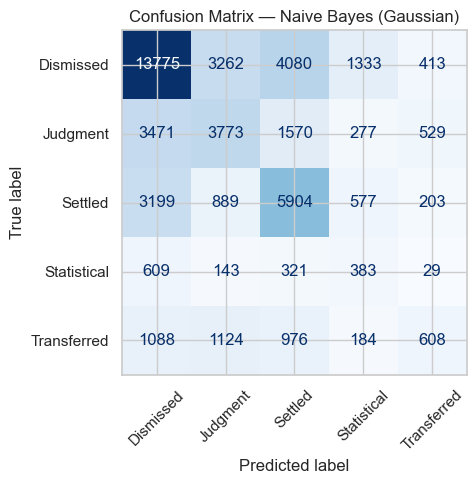

(0.5017036124794746,
 0.5066908747810341,
 0.5017036124794746,
 0.499741511399264,
 0.7189336843910188)

In [7]:
t0 = time.time()
nb_clf = GaussianNB()
nb_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_nb = nb_clf.predict(X_test_final)
proba_nb = nb_clf.predict_proba(X_test_final)

fitted_models_clf["Naive Bayes (Gaussian)"] = nb_clf
test_preds_clf["Naive Bayes (Gaussian)"] = pred_nb
test_probas_clf["Naive Bayes (Gaussian)"] = proba_nb

evaluate_classifier("Naive Bayes (Gaussian)", y_clf_test, pred_nb, proba_nb, fit_seconds,
                     classes=nb_clf.classes_.tolist())


===== Decision Tree Classifier =====
Accuracy=0.5445  Precision(weighted)=0.6201  Recall(weighted)=0.5445  F1(weighted)=0.5624  ROC-AUC(OvR, weighted)=0.8021  (fit time 9.0s)
              precision    recall  f1-score   support

   Dismissed       0.76      0.51      0.61     22863
    Judgment       0.62      0.53      0.57      9620
     Settled       0.50      0.67      0.57     10772
 Statistical       0.16      0.47      0.24      1485
 Transferred       0.30      0.50      0.37      3980

    accuracy                           0.54     48720
   macro avg       0.47      0.53      0.47     48720
weighted avg       0.62      0.54      0.56     48720



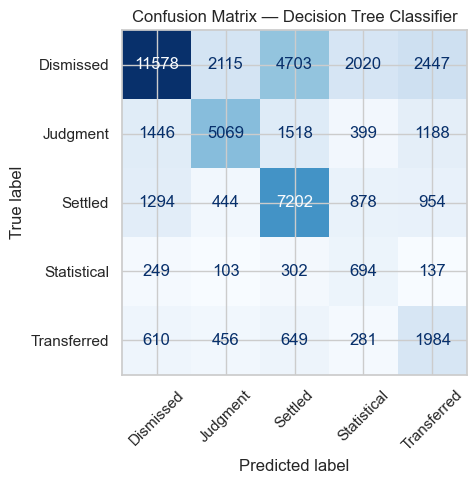

(0.5444786535303777,
 0.6201335694983382,
 0.5444786535303777,
 0.5623970057354155,
 0.8021333730394415)

In [8]:
t0 = time.time()
dt_clf = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=RANDOM_STATE)
dt_clf.fit(X_train_final, y_clf_train)
fit_seconds = time.time() - t0

pred_dt_clf = dt_clf.predict(X_test_final)
proba_dt_clf = dt_clf.predict_proba(X_test_final)

fitted_models_clf["Decision Tree Classifier"] = dt_clf
test_preds_clf["Decision Tree Classifier"] = pred_dt_clf
test_probas_clf["Decision Tree Classifier"] = proba_dt_clf

evaluate_classifier("Decision Tree Classifier", y_clf_test, pred_dt_clf, proba_dt_clf, fit_seconds,
                     classes=dt_clf.classes_.tolist())

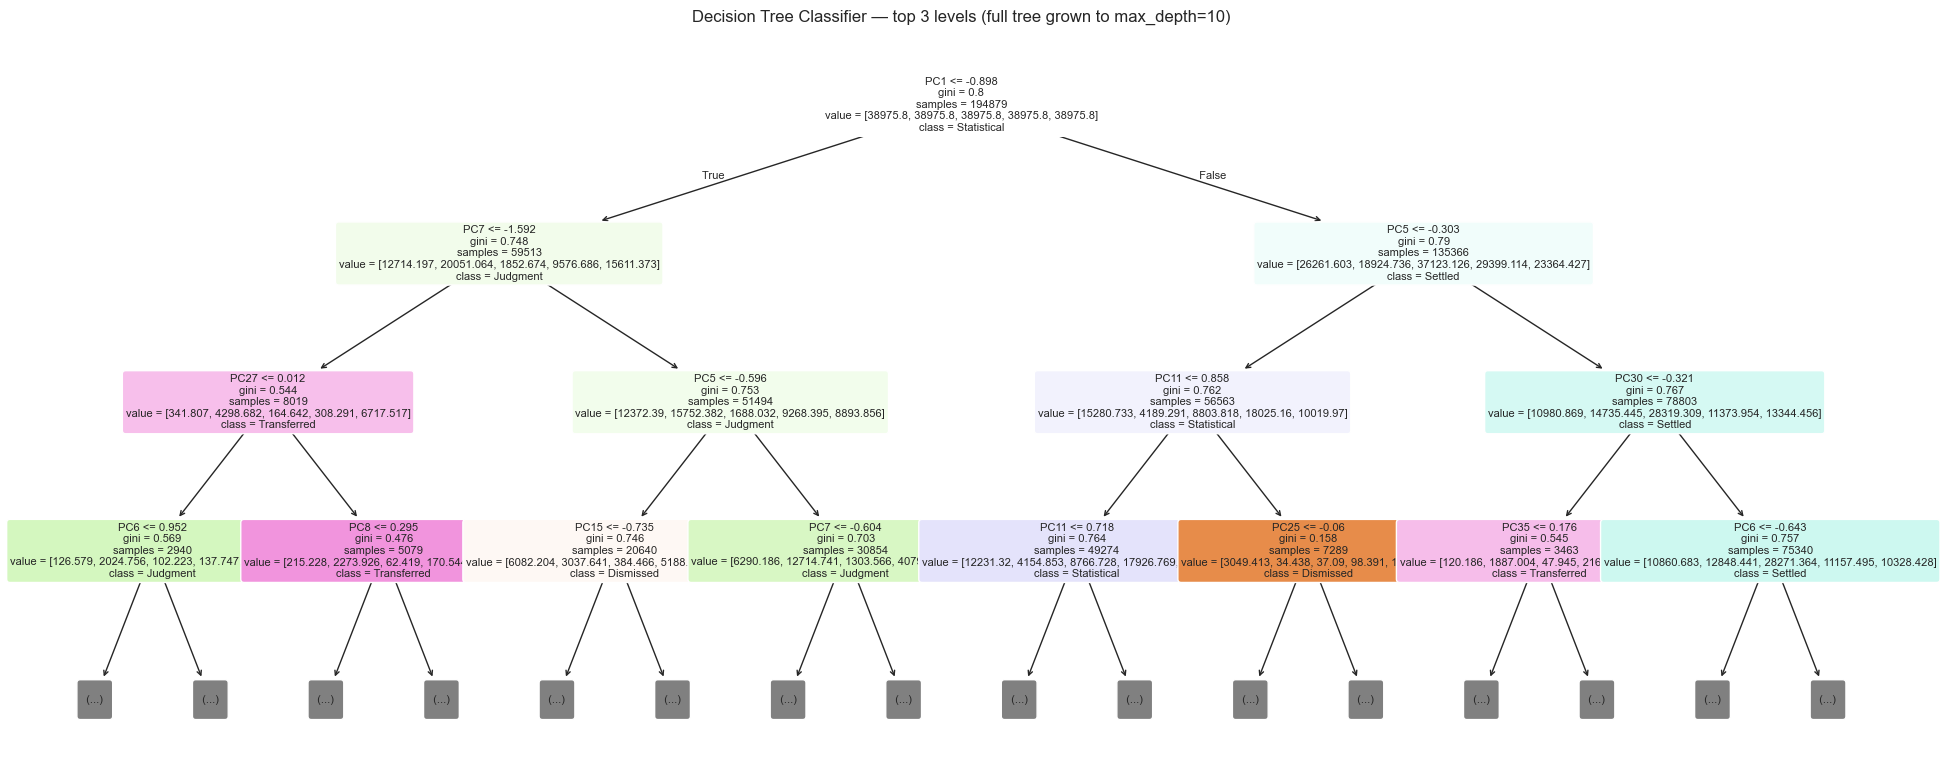

In [9]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt_clf, max_depth=3, feature_names=X_train_final.columns, class_names=dt_clf.classes_,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Decision Tree Classifier — top 3 levels (full tree grown to max_depth=10)")
plt.tight_layout()
plt.show()


===== SVC =====
Accuracy=0.5240  Precision(weighted)=0.6067  Recall(weighted)=0.5240  F1(weighted)=0.5370  ROC-AUC(OvR, weighted)=0.7995  (fit time 72.7s)
              precision    recall  f1-score   support

   Dismissed       0.78      0.46      0.58     22863
    Judgment       0.51      0.47      0.49      9620
     Settled       0.48      0.74      0.58     10772
 Statistical       0.14      0.39      0.20      1485
 Transferred       0.34      0.46      0.39      3980

    accuracy                           0.52     48720
   macro avg       0.45      0.51      0.45     48720
weighted avg       0.61      0.52      0.54     48720



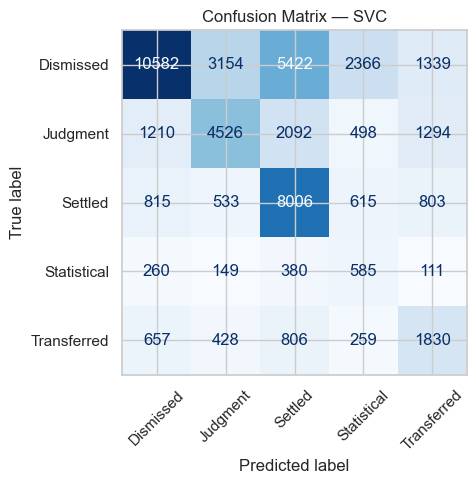

(0.5239942528735633,
 0.6067431771078464,
 0.5239942528735633,
 0.53696629968073,
 0.799467554750085)

In [10]:
t0 = time.time()
svc_clf = SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE)
svc_clf.fit(X_train_small, y_clf_train_small)   # same subsample as KNN, defined above
fit_seconds = time.time() - t0

pred_svc = svc_clf.predict(X_test_final)
proba_svc = svc_clf.predict_proba(X_test_final)

fitted_models_clf["SVC"] = svc_clf
test_preds_clf["SVC"] = pred_svc
test_probas_clf["SVC"] = proba_svc

evaluate_classifier("SVC", y_clf_test, pred_svc, proba_svc, fit_seconds, classes=svc_clf.classes_.tolist())

In [11]:
comparison_clf_df = pd.DataFrame(results_clf).drop_duplicates(subset="Model", keep="last")
comparison_clf_df = comparison_clf_df.sort_values("F1", ascending=False).reset_index(drop=True)
comparison_clf_df.index = comparison_clf_df.index + 1
comparison_clf_df.insert(0, "Rank", comparison_clf_df.index)
comparison_clf_df[["Rank", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC_OvR", "Fit_Seconds"]].round(4)

,Rank,Model,Accuracy,Precision,Recall,F1,ROC_AUC_OvR,Fit_Seconds
1,1,Decision Tree Classifier,0.5445,0.6201,0.5445,0.5624,0.8021,8.9570
2,2,KNN Classifier,0.5709,0.5597,0.5709,0.5578,0.7631,0.0166
3,3,SVC,0.5240,0.6067,0.5240,0.5370,0.7995,72.6528
4,4,Naive Bayes (Gaussian),0.5017,0.5067,0.5017,0.4997,0.7189,0.2751
5,5,Logistic Regression,0.4425,0.5654,0.4425,0.4637,0.7576,3.3298
